# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023.

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately.
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [17]:
!git clone https://github.com/kenedykimuhu-gif/dsc-course0-m8-lab.git
%cd dsc-course0-m8-lab

Cloning into 'dsc-course0-m8-lab'...
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 18 (delta 0), reused 0 (delta 0), pack-reused 15 (from 1)
Receiving objects: 100% (18/18), 4.91 MiB | 10.53 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/dsc-course0-m8-lab/dsc-course0-m8-lab/dsc-course0-m8-lab/dsc-course0-m8-lab/dsc-course0-m8-lab


In [19]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [20]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
df = pd.read_csv('/content/drive/MyDrive/cleaned_aviation_data.csv')

print(f"Successfully loaded cleaned data. Shape: {df.shape}")

Successfully loaded cleaned data. Shape: (71013, 28)


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types.

In [24]:
# creating the Size_Category column
df['Size_Category'] = np.where(df['Number.of.Engines'] >= 3, 'Large', 'Small')

# the number of accidents for each unique plane (Make_Model)
model_counts = df['Make_Model'].value_counts()

# the names of planes that have 20 or more accidents (Passenger threshold)
robust_models = model_counts[model_counts >= 20].index

# Filtering the dataframe to only keep these robust models
df_robust = df[df['Make_Model'].isin(robust_models)].copy()

# Separating into Small and Large
small_planes = df_robust[df_robust['Size_Category'] == 'Small']
large_planes = df_robust[df_robust['Size_Category'] == 'Large']

print(f"Total unique models with >= 20 accidents: {len(robust_models)}")
print(f"Total accidents for Small planes (robust): {len(small_planes)}")
print(f"Total accidents for Large planes (robust): {len(large_planes)}")

Total unique models with >= 20 accidents: 569
Total accidents for Small planes (robust): 54050
Total accidents for Large planes (robust): 174


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [28]:
# making sure the injury columns are numeric
injury_cols = ['Total.Fatal.Injuries', 'Total.Serious.Injuries', 'Total.Minor.Injuries', 'Total.Uninjured']
for col in injury_cols:
    df_robust[col] = pd.to_numeric(df_robust[col], errors='coerce').fillna(0)

# Now, we calculate the Total Passengers and the Fatal_Serious_Fraction
df_robust['Total.Passengers'] = df_robust[injury_cols].sum(axis=1)
df_robust['Fatal_Serious_Fraction'] = (
    (df_robust['Total.Fatal.Injuries'] + df_robust['Total.Serious.Injuries']) /
    (df_robust['Total.Passengers'] + 1e-9)
)

In [29]:
# Grouping the data by Size and Make, calculating the mean injury fraction
make_stats = df_robust.groupby(['Size_Category', 'Make']).agg(
    Total_Accidents=('Make', 'count'),
    Mean_Fatal_Serious_Fraction=('Fatal_Serious_Fraction', 'mean')
).reset_index()

# Getting the 15 safest SMALL makes (lowest mean fraction)
safe_small_makes = make_stats[make_stats['Size_Category'] == 'Small'].sort_values(
    by='Mean_Fatal_Serious_Fraction', ascending=True
).head(15)

# Getting the 15 safest LARGE makes (lowest mean fraction)
safe_large_makes = make_stats[make_stats['Size_Category'] == 'Large'].sort_values(
    by='Mean_Fatal_Serious_Fraction', ascending=True
).head(15)

print("--- Top 15 Safest SMALL Makes ---")
display(safe_small_makes)

print("\n--- Top 15 Safest LARGE Makes ---")
display(safe_large_makes)

--- Top 15 Safest SMALL Makes ---


,Size_Category,Make,Total_Accidents,Mean_Fatal_Serious_Fraction
16,Small,BOMBARDIER,29,0.003184
26,Small,EMBRAER,21,0.033072
6,Small,AIRBUS,137,0.059101
15,Small,BOEING,1274,0.068467
65,Small,SWEARINGEN,29,0.068966
47,Small,MCDONNELL DOUGLAS,161,0.087849
38,Small,GRUMMAN-SCHWEIZER,112,0.108631
31,Small,FAIRCHILD,24,0.109623
34,Small,GREAT LAKES,39,0.115385
27,Small,ENSTROM,157,0.141189



--- Top 15 Safest LARGE Makes ---


,Size_Category,Make,Total_Accidents,Mean_Fatal_Serious_Fraction
0,Large,BOEING,103,0.021821
2,Large,MCDONNELL DOUGLAS,69,0.024285
1,Large,CESSNA,2,0.750000


/tmp/ipykernel_1483/3741210480.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1483/3741210480.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


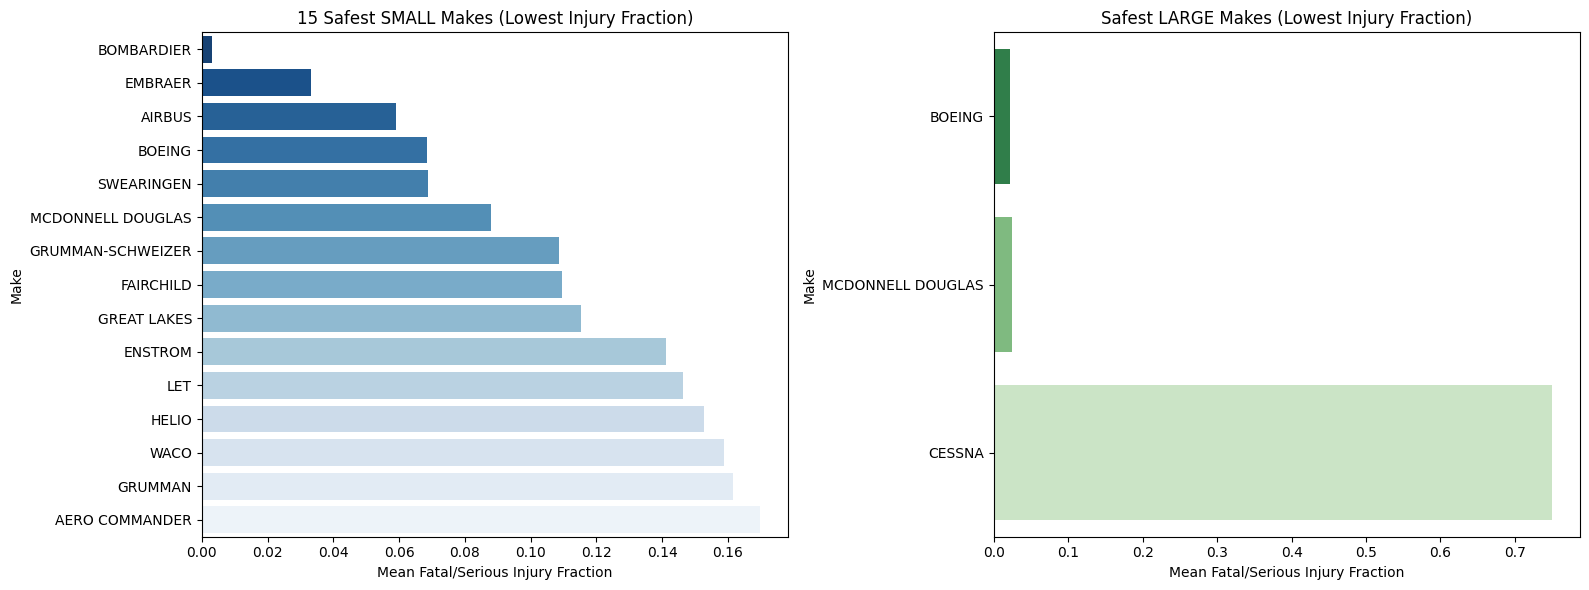

In [30]:
# Creating a figure with 1 row and 2 columns (side-by-side)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left Plot: Small Makes
sns.barplot(
    data=safe_small_makes,
    x='Mean_Fatal_Serious_Fraction',
    y='Make',
    ax=axes[0],
    palette='Blues_r'
)
axes[0].set_title('15 Safest SMALL Makes (Lowest Injury Fraction)')
axes[0].set_xlabel('Mean Fatal/Serious Injury Fraction')
axes[0].set_ylabel('Make')

# Right Plot: Large Makes
sns.barplot(
    data=safe_large_makes,
    x='Mean_Fatal_Serious_Fraction',
    y='Make',
    ax=axes[1],
    palette='Greens_r'
)
axes[1].set_title('Safest LARGE Makes (Lowest Injury Fraction)')
axes[1].set_xlabel('Mean Fatal/Serious Injury Fraction')
axes[1].set_ylabel('Make')

# Adjusting layout so titles and labels don't overlap
plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

/tmp/ipykernel_1483/3878207802.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


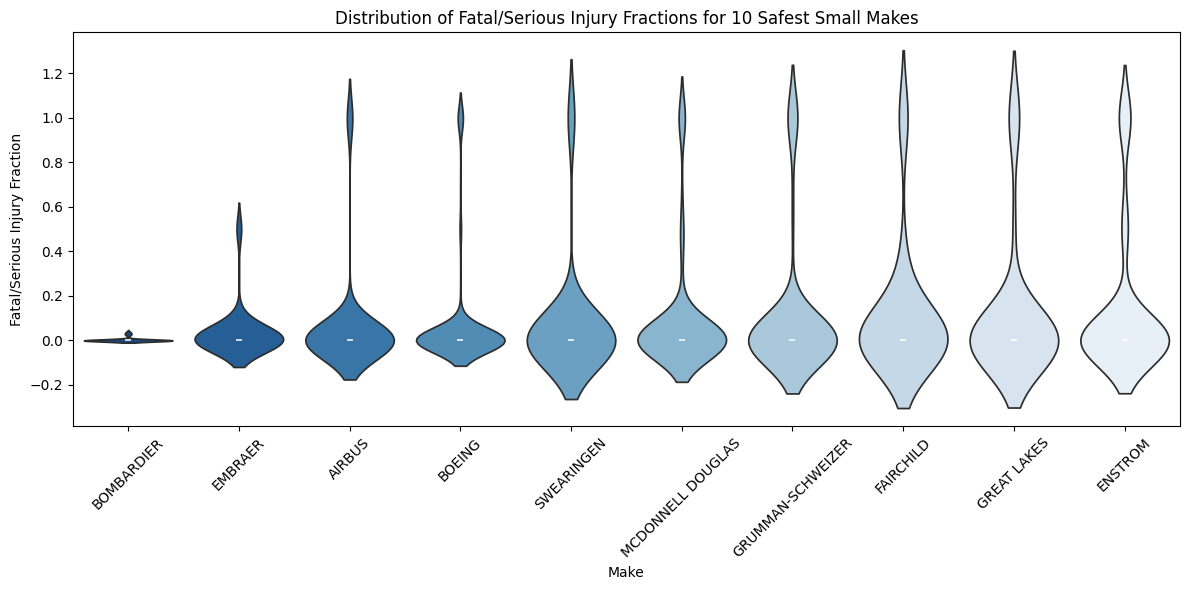

In [31]:
# the list of the 10 safest small makes from our previous table
top_10_small_makes = safe_small_makes.head(10)['Make'].tolist()

# Filtering the raw data for just these 10 makes
plot_data_small = df_robust[
    (df_robust['Size_Category'] == 'Small') &
    (df_robust['Make'].isin(top_10_small_makes))
]

# Creating the Violin Plot
plt.figure(figsize=(12, 6))
sns.violinplot(
    data=plot_data_small,
    x='Make',
    y='Fatal_Serious_Fraction',
    order=top_10_small_makes,
    palette='Blues_r'
)

plt.title('Distribution of Fatal/Serious Injury Fractions for 10 Safest Small Makes')
plt.xlabel('Make')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

/tmp/ipykernel_1483/37418441.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


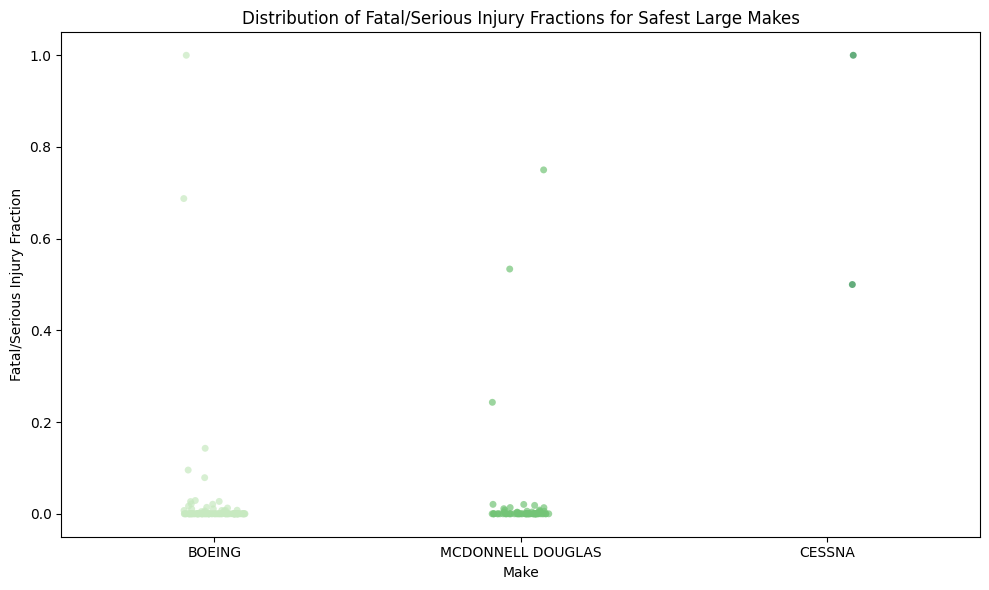

In [32]:
# the list of safest large makes
top_large_makes = safe_large_makes['Make'].tolist()

# Filtering the raw data for these makes
plot_data_large = df_robust[
    (df_robust['Size_Category'] == 'Large') &
    (df_robust['Make'].isin(top_large_makes))
]

# Creating the Strip Plot
plt.figure(figsize=(10, 6))
sns.stripplot(
    data=plot_data_large,
    x='Make',
    y='Fatal_Serious_Fraction',
    order=top_large_makes,
    jitter=True,
    size=5,
    alpha=0.7,
    palette='Greens'
)

plt.title('Distribution of Fatal/Serious Injury Fractions for Safest Large Makes')
plt.xlabel('Make')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.**

Sort your results and keep the lowest 15.

In [33]:
# the destruction rate along with injury stats
make_stats_destruction = df_robust.groupby(['Size_Category', 'Make']).agg(
    Total_Accidents=('Make', 'count'),
    Destruction_Rate=('Is_Destroyed', 'mean')
).reset_index()

# the lowest 15 destruction rates for SMALL makes
safe_small_destruction = make_stats_destruction[make_stats_destruction['Size_Category'] == 'Small'].sort_values(
    by='Destruction_Rate', ascending=True
).head(15)

# the lowest 15 destruction rates for LARGE makes
safe_large_destruction = make_stats_destruction[make_stats_destruction['Size_Category'] == 'Large'].sort_values(
    by='Destruction_Rate', ascending=True
).head(15)

print("--- 15 SMALL Makes with Lowest Destruction Rate ---")
display(safe_small_destruction)

print("\n--- LARGE Makes with Lowest Destruction Rate ---")
display(safe_large_destruction)

--- 15 SMALL Makes with Lowest Destruction Rate ---


,Size_Category,Make,Total_Accidents,Destruction_Rate
16,Small,BOMBARDIER,29,0.000000
26,Small,EMBRAER,21,0.000000
58,Small,ROCKWELL INTERNATIONAL,24,0.000000
36,Small,GRUMMAN ACFT ENG COR-SCHWEIZER,24,0.000000
24,Small,DIAMOND IND,23,0.043478
9,Small,AVIAT,113,0.044248
32,Small,FLIGHT DESIGN GMBH,45,0.044444
11,Small,BALLOON WORKS,39,0.051282
15,Small,BOEING,1274,0.053375
6,Small,AIRBUS,137,0.058394



--- LARGE Makes with Lowest Destruction Rate ---


,Size_Category,Make,Total_Accidents,Destruction_Rate
1,Large,CESSNA,2,0.000000
0,Large,BOEING,103,0.009709
2,Large,MCDONNELL DOUGLAS,69,0.028986


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

## **RECOMMENDATIONS:**
Considering the combined metrics of low fatal injuries and destruction rates, the following recommendations can be given to the clients:
1. For small aircrafts; Embraer and Bombardier seem to be highly safe as they had zero destruction rate and very low mean serious injury fractions. Airbus and Boeing also had good safety profiles having less than 6% destruction rates and injury fractions  less than 7%.

2. For the large ones; Boieng is the best recommendation with a mean fatal injury fraction  of just 2.1% and a destruction rate less yha 1%. McDonnell Douglas follows with a 2.4% injury fraction and 2.9% rate of destruction. Cessna has only 2 recorded accidents thus making its 0% rate of destruction insignificant.

## **Comment on Statistics and Distributions:**
 **Injury Distributions:** The plots for both the large and small makes show that even if the mean injury fraction is low for top makes, the data has a long tail. Majority of the accidents result in 0% fatal injuries but in almost every make, there are extreme outliers. This shows that they are generally safe but an accident's severity can be catastrophic.

 **Destruction vs Injury:** There is not always a perfect correlation between an aircraft being destroyed and passengers being hurt. Some small munitions, for example, have a low destruction rate but a higher injury fraction. This means that other factors (like phase of flight, weather or speed of impact) play a large part in survivability, whether the airframe survives or not.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

In [34]:
# Filtering for Large planes only
df_large = df[df['Size_Category'] == 'Large'].copy()

# accidents per model and keep only those with >= 10
large_model_counts = df_large['Make_Model'].value_counts()
robust_large_models = large_model_counts[large_model_counts >= 10].index

# final filtered dataframe
df_large_robust = df_large[df_large['Make_Model'].isin(robust_large_models)].copy()

print(f"Number of unique Large models with >= 10 accidents: {len(robust_large_models)}")
print("The models are:")
print(list(robust_large_models))

Number of unique Large models with >= 10 accidents: 17
The models are:
['BOEING 747', 'MCDONNELL DOUGLAS DC-10-10', 'BOEING 727-200', 'MCDONNELL DOUGLAS MD-11', 'BOEING 727-232', 'BOEING 727', 'MCDONNELL DOUGLAS DC-10-30', 'LOCKHEED L-1011-385-1', 'BOEING 727-223', 'BOEING 727-224', 'BOEING 747-400', 'BOEING 727-225', 'BOEING 747-422', 'BOEING 727-100', 'BOEING 747-200', 'MCDONNELL DOUGLAS MD-11F', 'LOCKHEED L-1011']


Both columns successfully created!


/tmp/ipykernel_1483/1479746653.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


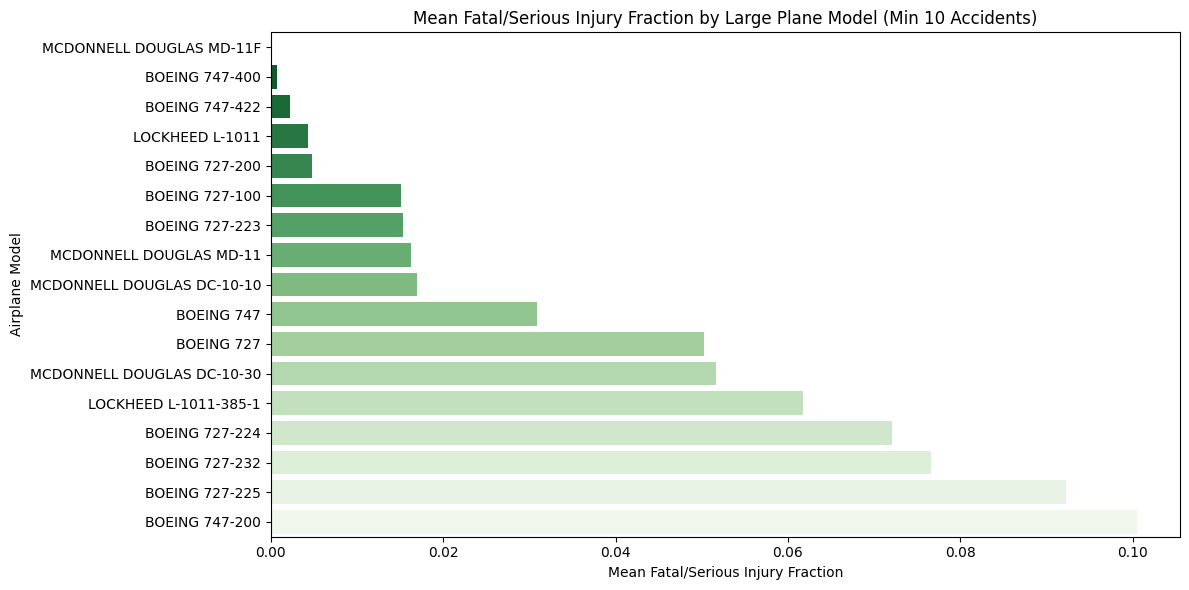

In [38]:
# Recreating Total.Passengers
injury_cols = ['Total.Fatal.Injuries', 'Total.Serious.Injuries', 'Total.Minor.Injuries', 'Total.Uninjured']
for col in injury_cols:
    df_large_robust[col] = pd.to_numeric(df_large_robust[col], errors='coerce').fillna(0)

df_large_robust['Total.Passengers'] = df_large_robust[injury_cols].sum(axis=1)

# Recreating Fatal_Serious_Fraction
df_large_robust['Fatal_Serious_Fraction'] = (
    (df_large_robust['Total.Fatal.Injuries'] + df_large_robust['Total.Serious.Injuries']) /
    (df_large_robust['Total.Passengers'] + 1e-9)
)

print("Both columns successfully created!")

# calculate the mean
large_model_means = df_large_robust.groupby('Make_Model')['Fatal_Serious_Fraction'].mean().reset_index()
large_model_means = large_model_means.sort_values(by='Fatal_Serious_Fraction', ascending=True)

# Plot it
plt.figure(figsize=(12, 6))
sns.barplot(
    data=large_model_means,
    x='Fatal_Serious_Fraction',
    y='Make_Model',
    palette='Greens_r'
)
plt.title('Mean Fatal/Serious Injury Fraction by Large Plane Model (Min 10 Accidents)')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Airplane Model')
plt.tight_layout()
plt.show()

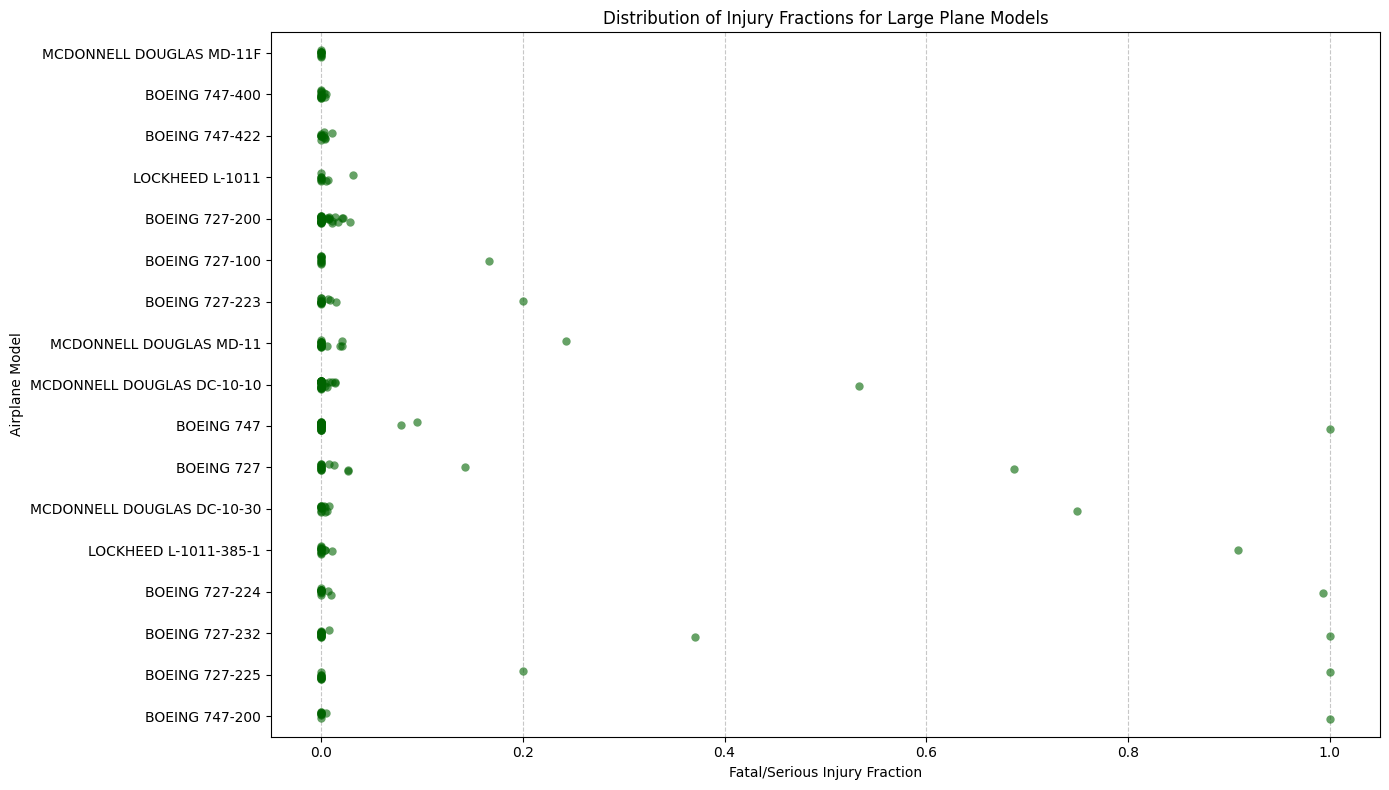

In [39]:
# Stripplot for the large plane models
plt.figure(figsize=(14, 8))

sns.stripplot(
    data=df_large_robust,
    x='Fatal_Serious_Fraction',
    y='Make_Model',
    order=large_model_means['Make_Model'],
    size=6,
    alpha=0.6,
    color='darkgreen'
)

plt.title('Distribution of Injury Fractions for Large Plane Models')
plt.xlabel('Fatal/Serious Injury Fraction')
plt.ylabel('Airplane Model')
plt.xlim(-0.05, 1.05)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

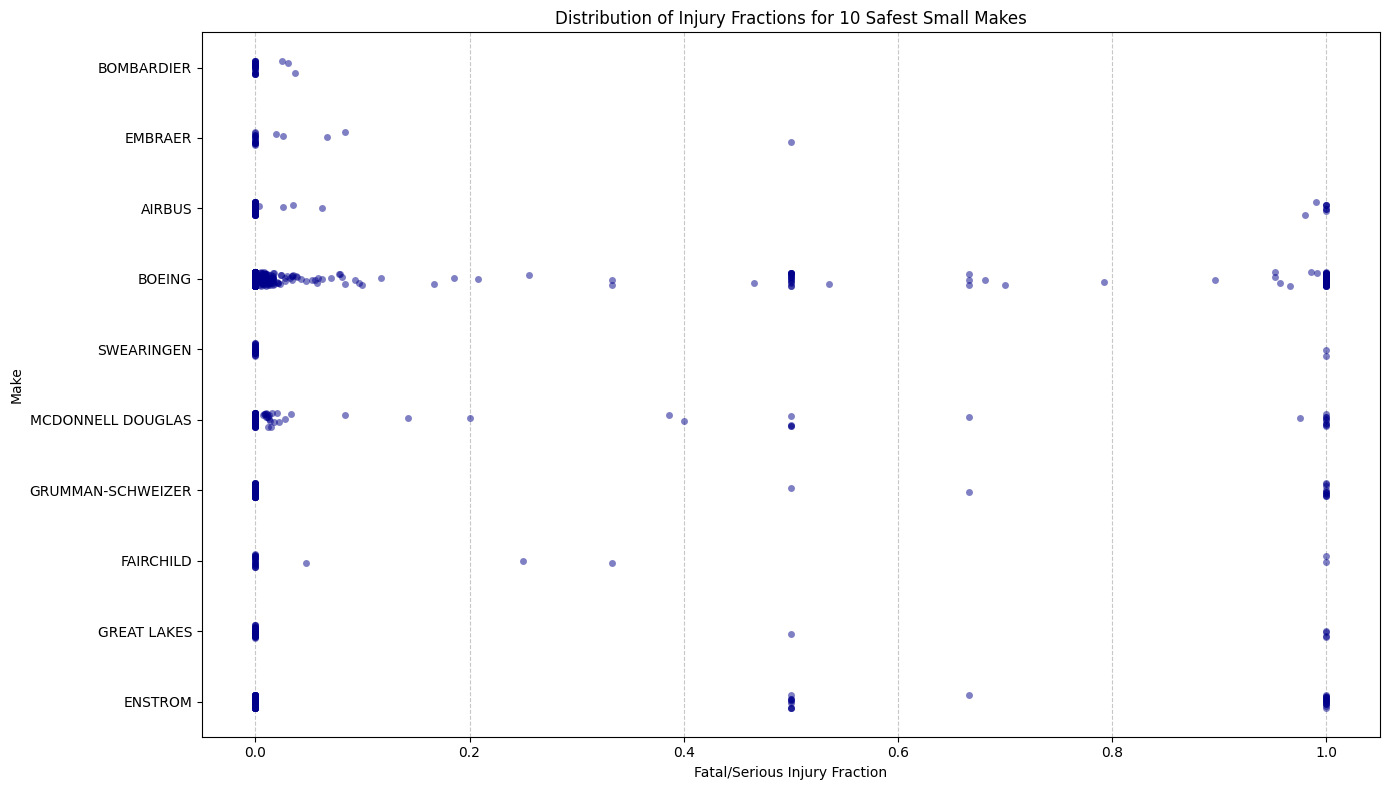

In [40]:
# list of the 10 saffest makes
top_10_small_makes = safe_small_makes.head(10)['Make'].tolist()
# Filtering the raw data for these makes
plot_data_small = df_robust[
    (df_robust['Size_Category'] == 'Small') &
    (df_robust['Make'].isin(top_10_small_makes))
]

# the Stripplot
plt.figure(figsize=(14, 8))
sns.stripplot(
    data=plot_data_small,
    x='Fatal_Serious_Fraction',
    y='Make',
    order=top_10_small_makes,
    size=5,
    alpha=0.5,
    color='darkblue'
)

plt.title('Distribution of Injury Fractions for 10 Safest Small Makes')
plt.xlabel('Fatal/Serious Injury Fraction')
plt.ylabel('Make')
plt.xlim(-0.05, 1.05)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

## **Discussion of Specific Airplane Types**
From the findings having considered only those having 10 or more accidents in order to make the results statistically reliable, we can state that:
**Larger Planes:** The mean injury fractions for larger planes show that McDonnell Douglas (specifically the MD-11F) and Boeing (747-400, 747-422) have the lowest rates of fatal injuries. But the stripplot tells us an important detail: even for these high rated models, there is a stark distribution. The vast majority of accidents have 0% severe injuries, but there are still individual catastrophic events that have 100% fatality. Older designs such as the Boeing 727 line demonstrated higher mean values of injury fraction, and this was possibly due to the age or time during which the aircraft was mainly operated.

**Smaller Airplanes:**  For smaller planes we isolated the 10 makes with the lowest mean injury fractions (including Bombardier, Embraer, and Airbus). The distribution plot for these makes has a very heavy concentration of accidents near 0.0. This means when these small aircrafts are involved in accidents, the vast majority of passengers escape with no serious injuries. However, just like the big planes, the long tail of dots out to 1.0 confirms that survivability is still very dependent on the particular circumstances of the crash (eg impact speed, terrain).

**Conclusion**
In terms of safety and insurance, it can be said that it is quite justified to recommend modern Bombardier, Embraer, and Boeing aircraft based on the results. But the existence of extremely high outliers for all aircrafts indicates that it is necessary to research other factors such as weather or flight phase.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

# **WEATHER CONDITION**

In [41]:
# stats for Weather Condition
weather_stats = df_robust.groupby('Weather.Condition').agg(
    Total_Accidents=('Weather.Condition', 'count'),
    Destruction_Rate=('Is_Destroyed', 'mean'),
    Severe_Injury_Rate=('Fatal_Serious_Fraction', 'mean')
).reset_index()

# RemovING the 'UNKNOWN' category for a clearer comparison
weather_stats = weather_stats[weather_stats['Weather.Condition'] != 'UNKNOWN']

print("--- Safety Stats by Weather Condition ---")
display(weather_stats)

--- Safety Stats by Weather Condition ---


,Weather.Condition,Total_Accidents,Destruction_Rate,Severe_Injury_Rate
0,IMC,3940,0.592132,0.680601
2,VMC,47089,0.162097,0.219441


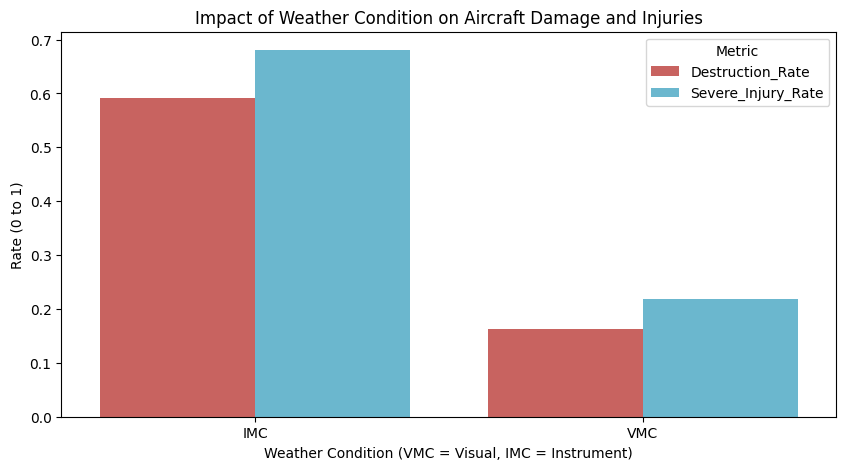

In [42]:
# Melting the dataframe to make it easier to plot both metrics side-by-side
weather_melted = weather_stats.melt(
    id_vars='Weather.Condition',
    value_vars=['Destruction_Rate', 'Severe_Injury_Rate'],
    var_name='Metric',
    value_name='Rate'
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=weather_melted,
    x='Weather.Condition',
    y='Rate',
    hue='Metric',
    palette=['#d9534f', '#5bc0de']
)
plt.title('Impact of Weather Condition on Aircraft Damage and Injuries')
plt.ylabel('Rate (0 to 1)')
plt.xlabel('Weather Condition (VMC = Visual, IMC = Instrument)')
plt.legend(title='Metric')
plt.show()

# **Phase of Flight**

In [43]:
# Calculating stats for Phase of Flight
phase_stats = df_robust.groupby('Broad.phase.of.flight').agg(
    Total_Accidents=('Broad.phase.of.flight', 'count'),
    Destruction_Rate=('Is_Destroyed', 'mean'),
    Severe_Injury_Rate=('Fatal_Serious_Fraction', 'mean')
).reset_index()

# Sorting by Severe Injury Rate to make the chart easier to read
phase_stats = phase_stats.sort_values(by='Severe_Injury_Rate', ascending=False).head(10)

print("--- Top 10 Phases of Flight by Severe Injury Rate ---")
display(phase_stats)

--- Top 10 Phases of Flight by Severe Injury Rate ---


,Broad.phase.of.flight,Total_Accidents,Destruction_Rate,Severe_Injury_Rate
12,UNKNOWN,317,0.728707,0.811777
6,MANEUVERING,4740,0.416878,0.469002
1,CLIMB,1205,0.405809,0.410143
8,OTHER,56,0.285714,0.388988
2,CRUISE,6641,0.334287,0.345515
0,APPROACH,3995,0.280100,0.329916
7,NAN,15116,0.129995,0.321043
3,DESCENT,1161,0.300603,0.317419
4,GO-AROUND,1006,0.279324,0.288597
10,TAKEOFF,7757,0.210648,0.220949


/tmp/ipykernel_1483/2103811627.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


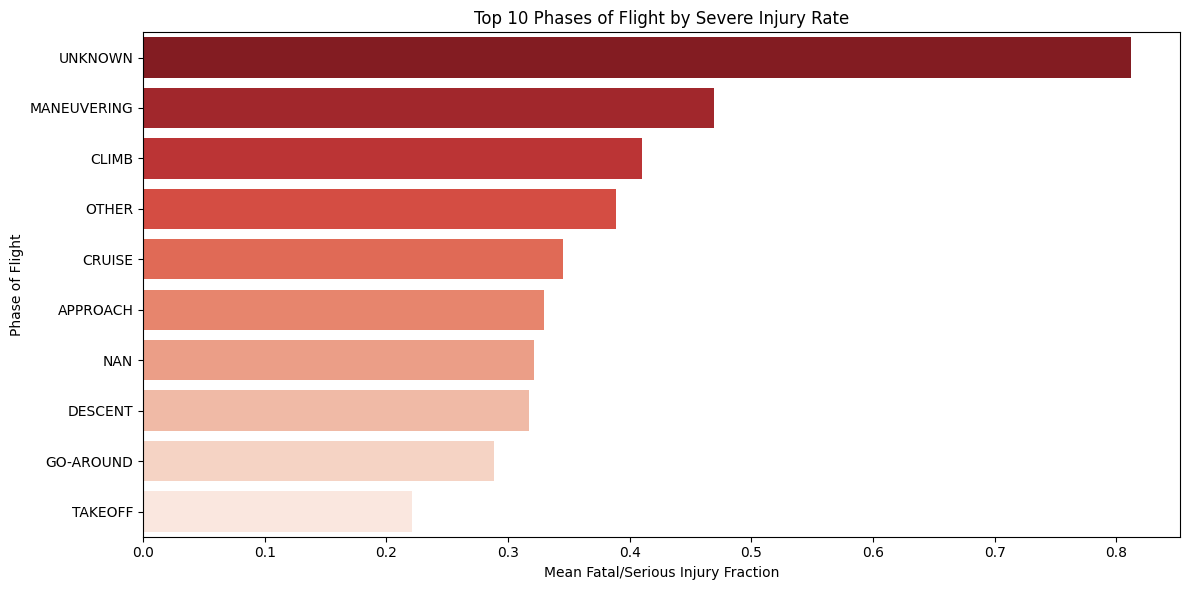

In [44]:
# Plotting the Severe Injury Rate by Phase of Flight
plt.figure(figsize=(12, 6))
sns.barplot(
    data=phase_stats,
    x='Severe_Injury_Rate',
    y='Broad.phase.of.flight',
    palette='Reds_r'
)
plt.title('Top 10 Phases of Flight by Severe Injury Rate')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Phase of Flight')
plt.tight_layout()
plt.show()

## **Discussion of Other Safety Factors**
# **1. Weather Condition**
We compaired accidents in VMC against IMC
**Findings:** The visualizations clearly show that accidents that occur in IMC have a significantly higher rate of both aircraft destruction and severe passenger injuries than those that occur in VMC.

**Interpretation:** This is likely because flying in poor weather requires instrument navigation and reduces the pilot's ability to see and avoid obstacles, and often involves flying through severe turbulence or icing conditions. For the insurer, this indicates adverse weather as a major risk multiplier for severe outcomes.

# **2. Phase of Flight**


## **Discussion of Other Safety Factors**
# **1. Weather Condition**
We compaired accidents in VMC against IMC
**Findings:** The visualizations clearly show that accidents that occur in IMC have a significantly higher rate of both aircraft destruction and severe passenger injuries than those that occur in VMC.

**Interpretation:** This is likely because flying in poor weather requires instrument navigation and reduces the pilot's ability to see and avoid obstacles, and often involves flying through severe turbulence or icing conditions. For the insurer, this indicates adverse weather as a major risk multiplier for severe outcomes.

# **2. Phase of Flight**
**Findings:** The data summary and bar chart show that some phases are far more deadly than others. “Landing” or “Taxi” accidents are very common, but have very low destruction and severe injury rates (low speed/energy). Conversely, phases like "Maneuvering" (low altitude, high speed) and "Approach" exhibit considerably higher severe injury fractions.

**Interpretation:** Phase of flight determines the level of kinetic energy and response time for the pilot. Accidents that happen in high energy phases like maneuvers or early climb don't leave any time to make mistakes or attempt an emergency landing. This clearly indicates that safety measures as well as insurance charges must consider the operational phase of the aircraft.

In [45]:
readme_content = """# Aviation Accident Analysis

## Project Overview
This project analyzes aviation accident data from 1983 to 2023 to identify aircraft makes and models with the lowest rates of total destruction and severe passenger injuries. The client (an airline/insurer) requested separate recommendations for small vs. large aircraft.

## Key Findings & Recommendations

### 1. Safest Aircraft Makes & Models
*   **Small Aircraft:** **Bombardier** and **Embraer** stood out with the lowest destruction rates (0.0%) and low injury fractions. **Airbus** and **Boeing** (smaller models) also performed exceptionally well.
*   **Large Aircraft:** **Boeing** and **McDonnell Douglas** demonstrated the safest profiles for large commercial jets, with Boeing showing a destruction rate under 1% and an injury fraction of ~2.1%.
*   **Note on Statistics:** Data distributions for all makes show that while the mean injury rate is low (most accidents result in 0 severe injuries), there are extreme outliers resulting in 100% fatality, highlighting that crash circumstances matter immensely.

### 2. Contributing Factors
*   **Weather:** Accidents in Instrument Meteorological Conditions (IMC / bad weather) resulted in significantly higher destruction and injury rates compared to clear weather (VMC).
*   **Phase of Flight:** Accidents during high-energy phases (e.g., Maneuvering, Approach) had far higher severe injury fractions than low-energy phases (e.g., Landing, Taxi).

## Tools Used
*   Python, Pandas, NumPy
*   Matplotlib, Seaborn
*   Google Colab / Jupyter Notebooks
"""

# Save it to the repo folder
with open('README.md', 'w') as f:
    f.write(readme_content)

print("✅ README.md created successfully!")

✅ README.md created successfully!
